In [125]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from fredapi import Fred
from sklearn.linear_model import LassoCV, LinearRegression
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler

In [71]:
fred_api_key = "67e29d02d4f169d6ecbbc366d4ea95c6"
fred = Fred(fred_api_key)
# FRED Data - Combined list of all desired series
fred_data_sources = {
    'AAAFF': 'AAAFF',
    'AAA10YM': 'AAA10YM',
    'BAAFF': 'BAAFF',
    'BAA10YM': 'BAA10YM',
    'EMPLOYMENT': 'CE16OV',
    'EFFR': 'FEDFUNDS',
    'FPI': 'FPI',
    'GDP': 'GDP',
    'GDP_DEF': 'GDPDEF',
    '10Y': 'GS10',  # Long Term Yield
    'M2': 'M2SL',
    'PCE': 'PCEC',
    'UNEMPLOYMENT': 'UNRATE',
    'PCE_PRICE_INDEX': 'PCEPI',  # For inflation calculation
    '2Y': 'GS2',  # Short Term Yield
    'USD_INDEX': 'TWEXB'  # Broad Trade Weighted US Dollar Index
}

all_fred_dataframes = []
for col_name, series_id in fred_data_sources.items():
    df = pd.DataFrame(fred.get_series(series_id), columns=[col_name])
    all_fred_dataframes.append(df)

# Merge FRED data using an OUTER merge for broader date range
if not all_fred_dataframes:
    raise RuntimeError("No FRED dataframes to merge.")

merged_df = all_fred_dataframes[0]
for df in all_fred_dataframes[1:]:
    merged_df = pd.merge(merged_df, df, left_index=True, right_index=True, how='outer')

# Data Pre-processing for VAR
# 1. Ensure all data is numeric and handle NaNs at the original frequency first
merged_df = merged_df.apply(pd.to_numeric, errors='coerce')
merged_df.ffill(inplace=True)  # Forward-fill any NaNs
merged_df.bfill(inplace=True)  # Backward-fill remaining NaNs (e.g., at the start)
merged_df.dropna(inplace=True)  # Drop any rows that are still all NaN after filling

# 2. Resample all series to a consistent quarterly frequency ('QS' - Quarter Start)
# Taking the last observation of the quarter for all series
merged_df_quarterly = merged_df.resample('QE').last()

# 3. Suppress yield into actual value, also convert into spread format
# BBB = AAA + BBB_AAA_spread ; AAA = EFFR+ AAA_spread

merged_df_quarterly['AAA_SPREAD_FF'] = merged_df_quarterly['AAAFF'] - merged_df_quarterly['EFFR']
merged_df_quarterly['AAA_SPREAD_10Y'] = merged_df_quarterly['AAA10YM'] - merged_df_quarterly['EFFR']
merged_df_quarterly['BAA_AAA_SPREAD_FF'] = merged_df_quarterly['BAAFF'] - merged_df_quarterly['AAAFF']
merged_df_quarterly['BAA_AAA_SPREAD_10Y'] = merged_df_quarterly['BAA10YM'] - merged_df_quarterly['AAA10YM']

In [142]:
# 4. Identify variables that should be log-transformed to ensure no negative rate/spread
log_transform_vars = ['EFFR', '10Y', '2Y', 'AAA_SPREAD_FF', 'AAA_SPREAD_10Y', 'BAA_AAA_SPREAD_FF',
                        'BAA_AAA_SPREAD_10Y']
for col in log_transform_vars:
    if col in merged_df_quarterly.columns:
        np.log(merged_df_quarterly[col])

/Users/chingfungleung/miniconda3/envs/islp/lib/python3.10/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [144]:
merged_df_quarterly[['EFFR', '10Y', '2Y', 'AAA_SPREAD_FF', 'AAA_SPREAD_10Y', 'BAA_AAA_SPREAD_FF',
                        'BAA_AAA_SPREAD_10Y']]

,EFFR,10Y,2Y,AAA_SPREAD_FF,AAA_SPREAD_10Y,BAA_AAA_SPREAD_FF,BAA_AAA_SPREAD_10Y
1939-03-31,0.80,2.83,7.06,1.78,-0.40,0.04,0.42
1939-06-30,0.80,2.83,7.06,1.78,-0.40,0.04,0.42
1939-09-30,0.80,2.83,7.06,1.78,-0.40,0.04,0.42
1939-12-31,0.80,2.83,7.06,1.78,-0.40,0.04,0.42
1940-03-31,0.80,2.83,7.06,1.78,-0.40,0.04,0.42
...,...,...,...,...,...,...,...
2024-06-30,5.33,4.31,4.74,-5.47,-4.51,0.72,0.69
2024-09-30,5.13,3.72,3.62,-5.24,-4.17,0.72,0.74
2024-12-31,4.48,4.39,4.23,-3.41,-3.67,0.60,0.60
2025-03-31,4.33,4.28,3.97,-3.35,-3.32,0.68,0.64


In [ ]:
merged_df_quarterly
merged_df_quarterly.to_csv("macro.csv")

In [ ]:
# features: macro and fundamentals: pct change of total liabilities OR previous interest expense / total liabilities
# target: pct_change of interest expense OR interest expense / total liabilities

In [108]:
# Macro data
macro = pd.read_csv("macro.csv", index_col=0)
macro_non_stationary_cols = ['EMPLOYMENT', 'FPI', 'GDP', 'GDP_DEF', 'M2', 'PCE', 'PCE_PRICE_INDEX']
for col in macro_non_stationary_cols:
    macro[f'{col}_pct_change'] = macro.loc[:, col].pct_change()

# Remove non-stationary columns
macro.drop(columns=macro_non_stationary_cols, inplace=True)

macro.info()

<class 'pandas.core.frame.DataFrame'>
Index: 346 entries, 1939-03-31 to 2025-06-30
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   AAAFF                       346 non-null    float64
 1   AAA10YM                     346 non-null    float64
 2   BAAFF                       346 non-null    float64
 3   BAA10YM                     346 non-null    float64
 4   EFFR                        346 non-null    float64
 5   10Y                         346 non-null    float64
 6   UNEMPLOYMENT                346 non-null    float64
 7   2Y                          346 non-null    float64
 8   USD_INDEX                   346 non-null    float64
 9   AAA_SPREAD_FF               346 non-null    float64
 10  AAA_SPREAD_10Y              346 non-null    float64
 11  BAA_AAA_SPREAD_FF           346 non-null    float64
 12  BAA_AAA_SPREAD_10Y          346 non-null    float64
 13  EMPLOYMENT_pct_change   

In [115]:
# Fundamental data
ko = pd.read_csv("KO_quarterly.csv", index_col=1)
if "Unnamed: 0" in ko.columns:
    ko.drop(columns="Unnamed: 0", inplace=True)
ko = ko[::-1]
ko = ko.loc[:, ['totalLiabilities', 'interestExpense']]
ko['totalLiabilitiesPctChange'] = ko.loc[:, 'totalLiabilities'].pct_change()
ko['interestExpensePctChange'] = ko.loc[:, 'interestExpense'].pct_change()
ko['interestExpenseToDebtRatio'] = ko.loc[:, 'interestExpense'] / ko.loc[:, 'totalLiabilities']
ko['fwdInterestExpenseToDebtRatio'] = ko['interestExpenseToDebtRatio'].shift(-1)

# Drop non-stationary columns
ko.drop(columns=['totalLiabilities', 'interestExpense'], inplace=True)

In [ ]:
# Preprocess features and targets
Xy = pd.merge(macro, ko, left_index=True, right_index=True, how='outer')
Xy.dropna(inplace=True)
X = Xy.drop(columns='fwdInterestExpenseToDebtRatio')
y = Xy['fwdInterestExpenseToDebtRatio']

Lasso Optimal alpha: 0.0006
Lasso Coefficients: [-0.00000000e+00 -0.00000000e+00 -0.00000000e+00 -0.00000000e+00
  0.00000000e+00  0.00000000e+00 -0.00000000e+00  0.00000000e+00
  0.00000000e+00 -3.35164901e-05 -0.00000000e+00  0.00000000e+00
  0.00000000e+00 -0.00000000e+00 -0.00000000e+00 -0.00000000e+00
  0.00000000e+00  0.00000000e+00 -0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00  5.92661451e-05]
Selected features by Lasso: ['AAA_SPREAD_FF', 'interestExpenseToDebtRatio']
OLS coefficients: [-0.00052449  0.00055024]
OLS intercept: 0.003916742889043211
OLS R2: 0.19662075939845713


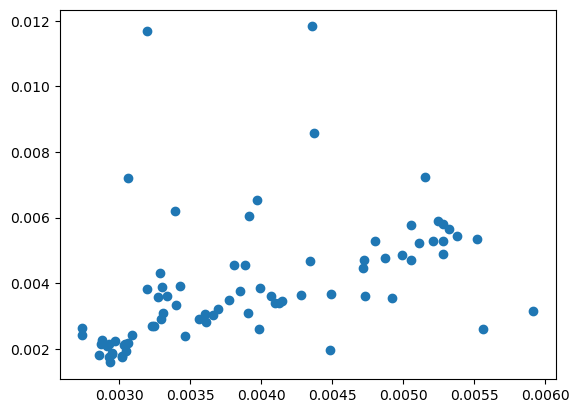

In [140]:
# Define parameters
n_samples = X.shape[0]
min_train_size = 20  
test_size = 5  
n_splits = (n_samples - min_train_size) // test_size 

# Create expanding window cross-validator
tscv = TimeSeriesSplit(
    n_splits=n_splits,
    test_size=test_size,
    gap=0  
)

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Initialize and fit LassoCV
lasso = LassoCV(
    alphas=np.logspace(-4, 0, 100),  
    cv=tscv,  
    random_state=0,
    n_jobs=-1  
)
lasso.fit(X_scaled, y)

# Best alpha and coefficients
print(f"Lasso Optimal alpha: {lasso.alpha_:.4f}")
print("Lasso Coefficients:", lasso.coef_)

# Identify selected features (non-zero coefficients)
coef = lasso.coef_
selected_mask = coef != 0
selected_features = X.columns[selected_mask]

print(f"Selected features by Lasso: {list(selected_features)}")

# Refit OLS on selected features using entire dataset
new_X = X.loc[:, selected_features]
new_scaler = StandardScaler()
new_X_scaled = new_scaler.fit_transform(new_X)

# Fit OLS (LinearRegression)
ols = LinearRegression().fit(new_X_scaled, y)

# Display results
print("OLS coefficients:", ols.coef_)
print("OLS intercept:", ols.intercept_)
print("OLS R2:", ols.score(new_X_scaled, y))

y_pred = ols.predict(new_X_scaled)
plt.scatter(y_pred, y)
plt.show()